# RL for adaptive eavesdropping on E91 — DIQKD analog of `QKD_experiment_5`

This is the **E91 / DIQKD extension** of the BB84 library-based eavesdropping experiment. Same overall structure as `QKD_experiment_5.ipynb`, but the protocol and noise model change:

| | BB84 (exp_5) | E91 (this notebook) |
|---|---|---|
| Protocol | Prepare-and-measure, 4 BB84 states | Entanglement-based, CHSH game |
| Channel noise | Bit-flip on Bob's qubit, rate `p_bf` | **Bilateral depolarizing** $\Lambda_p^A \otimes \Lambda_p^B$ on the entangled pair |
| Public observable | Bob's QBER, target $F_{AB} \geq 0.87$ | CHSH violation, target $S \geq S_{\text{sec}} + 0.02 \approx 2.444$ |
| Eve's information | $F_{AE}$ (Alice-Eve fidelity) | $\chi(A:E)$ (Holevo) |
| OU drift | $\mu=0.10, \sigma=0.03, p \in [0.01, 0.30]$ | $\mu=0.03, \sigma=0.015, p \in [0, 0.064]$ |
| Library | 4 fidelity targets × 6 anchors = 24 cells + identity | **7 absolute S targets** × 4 anchors = 26 cells + identity |

**Library targets** (7 levels): `safer/safer2/safe/medium1/medium/medium2/agg = (S=2.55 / 2.50 / 2.43 / 2.30 / 2.20 / 2.00 / 1.80)`. Finer-than-BB84-analog Pareto sampling: above threshold (`safer`, `safer2`), at threshold (`safe`), graduated below (`medium1`, `medium`, `medium2`, `agg`). Below-threshold cells can only be used when channel noise gives cover — Eve must learn to spend them strategically.

**Three policies compared**:
- **DP (analytical)** — Bellman-optimal over the library action set under OU drift
- **Oracle (greedy)** — projected-windowed-mean greedy over the library
- **PPO** — RL agent trained against the library env

All run on the same 50-step episodes.

## Imports

In [1]:
import os, math, pickle, time
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

import gymnasium as gym
from gymnasium import spaces
from stable_baselines3 import PPO
from stable_baselines3.common.callbacks import BaseCallback

from scipy.optimize import brentq
from numpy.polynomial.hermite_e import hermegauss

import evoluspsa_e91 as _e91
from evoluspsa_e91 import (
    circuit_to_unitary, STD_SETTINGS, obs as _pauli_obs,
    von_neumann_entropy, secure_key_rate,
)

torch.set_default_dtype(torch.float64)
C = torch.complex128

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


## Config

Threshold from the DIQKD secure key rate: $r(S) > 0$ requires $S > S_{\text{sec}} \approx 2.4240$. We set the operational detection threshold one finite-statistics buffer above:

$$\text{DET\_THRESH} = S_{\text{sec}} + 0.02 \approx 2.444$$

and the cliff $p_{\text{cliff}} = 1 - \sqrt{S_{\text{sec}} / 2\sqrt{2}} \approx 0.0742$ where the honest Bell pair just meets the threshold.

In [2]:
# Thresholds
S_SEC       = brentq(lambda s: secure_key_rate(s) - 1e-6, 2.01, 2.8)
DET_MARGIN  = 0.02
DET_THRESH  = S_SEC + DET_MARGIN
P_CLIFF     = 1 - np.sqrt(S_SEC / (2 * np.sqrt(2)))

# Library (absolute S targets, mirror of exp_5's F targets {0.90, 0.87, 0.80, 0.60})
S_ABS_TARGETS = {'safer': 2.55, 'safer2': 2.50, 'safe': 2.43, 'medium1': 2.30,
                 'medium': 2.20, 'medium2': 2.00, 'agg': 1.80}
P_GRID        = np.linspace(0.0, P_CLIFF - 0.01, 4)   # [0, 0.021, 0.043, 0.064]
FEAS_MARGIN   = 0.01
LIB_PATH      = 'e91_library_pathB_7levels.pkl'

# Per-action (S, χ) interpolation grid (used by DP and env)
P_INTERP = np.linspace(0.0, P_CLIFF - 0.005, 16)

# OU + episode
P_MU, P_KAPPA, P_SIGMA = 0.03, 0.1, 0.015
P_MIN, P_MAX           = 0.0, P_CLIFF - 0.01
EPISODE_LEN            = 50
WIN_S, HIST_LEN        = 10, 3

# Reward shaping (mirrors exp_5)
CHI_COEF, VIOL_COEF, MARGIN_COEF = 1.0, 3.0, 2.0
MARGIN_TOL, DET_PENALTY = 0.02, 30.0

# Training
TRAIN_STEPS, EVAL_EVERY, TEST_EPS = 2000_000, 10_000, 50
ENT_COEF, SEED = 0.10, 42

print(f'S_sec      = {S_SEC:.4f}')
print(f'DET_THRESH = {DET_THRESH:.4f}')
print(f'P_CLIFF    = {P_CLIFF:.5f}')
print(f'P_GRID     = {[f"{p:.4f}" for p in P_GRID]}')
print(f'S targets  = {S_ABS_TARGETS}')

S_sec      = 2.4240
DET_THRESH = 2.4440
P_CLIFF    = 0.07425
P_GRID     = ['0.0000', '0.0214', '0.0428', '0.0642']
S targets  = {'safer': 2.55, 'safer2': 2.5, 'safe': 2.43, 'medium1': 2.3, 'medium': 2.2, 'medium2': 2.0, 'agg': 1.8}


## Physics — bilateral depolarizing channel + noisy CHSH/Holevo

Eve prepares any tripartite state $|\psi_{ABE}\rangle$. Alice & Bob's qubits each pass through an independent depolarizing channel of strength $p$:

$$\rho_{ABE}^{\text{obs}}(U, p) = (\Lambda_p^A \otimes \Lambda_p^B \otimes \mathbb{I}_E)\,|\psi_{ABE}\rangle\langle\psi_{ABE}|$$

$\Lambda_p$ damps every non-identity Pauli by $(1-p)$. Honest reference: for the Bell pair $|\Phi^+\rangle$, $S_{\text{obs}}(p) = (1-p)^2 \cdot 2\sqrt{2}$ exactly.

**Why bilateral on A and B?** Λ_A reduces Eve's χ via DPI on Alice's measurement outcome; Λ_B leaves χ untouched but eats into the CHSH budget Eve must keep above DET_THRESH. The two channels constrain Eve through *separate* mechanisms — the bilateral spec is what gives DIQKD a non-trivial threat surface.

In [3]:
_I2 = torch.eye(2, dtype=C)
_X = torch.tensor([[0,1],[1,0]], dtype=C)
_Y = torch.tensor([[0,-1j],[1j,0]], dtype=C)
_Z = torch.tensor([[1,0],[0,-1]], dtype=C)
_PAULIS = [_I2, _X, _Y, _Z]

def _embed_on(G, which):
    ops = [_I2, _I2, _I2]; ops[which] = G
    return torch.kron(torch.kron(ops[0], ops[1]), ops[2])
_EMB_A = [_embed_on(G, 0) for G in _PAULIS]
_EMB_B = [_embed_on(G, 1) for G in _PAULIS]

def depolarize_ab(rho_abe, p):
    if p <= 0: return rho_abe
    s0, s1 = math.sqrt(1 - 3*p/4), math.sqrt(p/4)
    coefs = [s0, s1, s1, s1]
    tmp = torch.zeros_like(rho_abe)
    for c, K0 in zip(coefs, _EMB_A):
        K = c * K0; tmp = tmp + K @ rho_abe @ K.conj().T
    out = torch.zeros_like(tmp)
    for c, K0 in zip(coefs, _EMB_B):
        K = c * K0; out = out + K @ tmp @ K.conj().T
    return out

def compute_holevo_and_S_noisy(U, settings, p):
    psi = U @ torch.zeros(8, dtype=C).index_fill(0, torch.tensor([0]), 1.0)
    rho = torch.outer(psi, psi.conj())
    rho = depolarize_ab(rho, p)
    a1, a2, b1, b2 = (torch.tensor(s, dtype=torch.float64) for s in settings)
    rho_AB = torch.zeros(4, 4, dtype=C)
    for a in range(2):
      for b in range(2):
        for ap in range(2):
          for bp in range(2):
            rho_AB[a*2+b, ap*2+bp] = (
                rho[a*4+b*2+0, ap*4+bp*2+0] + rho[a*4+b*2+1, ap*4+bp*2+1])
    def E_corr(ai, bj):
        return torch.trace(rho_AB @ torch.kron(_pauli_obs(ai), _pauli_obs(bj))).real
    S = E_corr(a1, b1) + E_corr(a1, b2) + E_corr(a2, b1) - E_corr(a2, b2)
    rho_E = torch.zeros(2, 2, dtype=C)
    for e in range(2):
      for ep in range(2):
        for a in range(2):
          for b in range(2):
            rho_E[e, ep] += rho[a*4+b*2+e, a*4+b*2+ep]
    rho_E_cond, probs = [], []
    for x in range(2):
      rho_ex = torch.zeros(2, 2, dtype=C)
      for e in range(2):
        for ep in range(2):
          for b in range(2):
            rho_ex[e, ep] += rho[x*4+b*2+e, x*4+b*2+ep]
      px = torch.trace(rho_ex).real.clamp(min=1e-12)
      probs.append(px); rho_E_cond.append(rho_ex / px)
    chi = von_neumann_entropy(rho_E)
    for x in range(2):
        chi = chi - probs[x] * von_neumann_entropy(rho_E_cond[x])
    return float(S.item()), float(chi.item())

### Sanity: honest Bell pair → $S(p) = (1-p)^2 \cdot 2\sqrt{2}$, $\chi = 0$

In [4]:
# Build honest |Φ⁺⟩_AB ⊗ |0⟩_E and a unitary U* that reaches it from |000⟩
phi_plus_e0 = torch.zeros(8, dtype=C)
phi_plus_e0[0] = 1 / math.sqrt(2)       # |000⟩
phi_plus_e0[6] = 1 / math.sqrt(2)       # |110⟩
M = torch.randn(8, 8, dtype=C) + 1j * torch.randn(8, 8, dtype=C)
M[:, 0] = phi_plus_e0
Q, _ = torch.linalg.qr(M); Q[:, 0] = phi_plus_e0
U_star = Q

print(f"{'p':>6}  {'S_obs':>10}  {'(1-p)²·2√2':>12}  {'χ_obs':>10}")
for p in [0.0, 0.01, 0.03, 0.05, P_CLIFF, 0.10]:
    S, chi = compute_holevo_and_S_noisy(U_star, STD_SETTINGS, float(p))
    pred = (1 - p)**2 * 2 * math.sqrt(2)
    print(f'{p:>6.4f}  {S:>10.6f}  {pred:>12.6f}  {chi:>10.6f}')

     p       S_obs    (1-p)²·2√2       χ_obs
0.0000    2.828427      2.828427    0.000000
0.0100    2.772141      2.772141    0.000000
0.0300    2.661267      2.661267    0.000000
0.0500    2.552655      2.552655    0.000000
0.0742    2.424009      2.424009    0.000000
0.1000    2.291026      2.291026    0.000000


## Library — Path B (absolute S targets)

For each `(p_anchor, level)`, build a circuit that reaches `S = S_ABS_TARGETS[level]` with maximum χ via CMA-ES + SPSA. Cells where the target exceeds the honest curve at that p (`s_honest(p) - FEAS_MARGIN < target`) are skipped.

The evolutive search machinery comes from `evoluspsa_e91.py`. We monkey-patch its fitness function so it scores against the noisy `(S, χ)` at the current p anchor.

In [5]:
def s_honest(p): return (1 - p)**2 * 2 * math.sqrt(2)
def feasible(target, p): return target <= s_honest(p) - FEAS_MARGIN

cells_to_build = [(float(p), lvl, t)
                  for p in P_GRID for lvl, t in S_ABS_TARGETS.items()
                  if feasible(t, float(p))]
print(f'{len(cells_to_build)} cells to build (out of {len(P_GRID)*len(S_ABS_TARGETS)} possible)')

# Monkey-patch fitness to score on noisy (S, χ) at the cell's anchor
_CURRENT_P = 0.0
def _fitness_noisy(individual, s_target, alpha=_e91.ALPHA, beta=_e91.BETA):
    circuit, settings = individual
    try:
        U = circuit_to_unitary(circuit)
        S, chi = compute_holevo_and_S_noisy(U, settings, _CURRENT_P)
        return chi - alpha*(S - s_target)**2 - beta*len(circuit), S, chi
    except Exception:
        return -1e6, 0.0, 0.0
_e91.fitness = _fitness_noisy

def _run_at_p(s_target, p, **kwargs):
    global _CURRENT_P
    _CURRENT_P = float(p)
    return _e91.run_evoluspsa(s_target, **kwargs)

if os.path.exists(LIB_PATH):
    library = pickle.load(open(LIB_PATH, 'rb'))
    print(f'Loaded cached {LIB_PATH}: {len(library)} cells')
else:
    library = {}
    for i, (p, lvl, s_tgt) in enumerate(cells_to_build, 1):
        seeds = []
        for seed in range(2):
            r = _run_at_p(s_tgt, p, seed=seed*1000+hash(lvl)%997,
                          pop_size=30, n_epochs=25, spsa_iters=40,
                          alpha=100.0, beta=0.0,
                          variable_settings=False, verbose=False)
            seeds.append(r)
        best = max(seeds, key=lambda r: r['best_fitness'])
        library[(p, lvl)] = {
            'circuit': best['best_circuit'], 'settings': best['best_settings'],
            'S_at_p': best['best_S'], 'chi_at_p': best['best_chi'],
            'n_gates': best['best_n_gates'], 's_target': s_tgt,
        }
        print(f'[{i}/{len(cells_to_build)}] p={p:.3f} lvl={lvl:>6}: '
              f'S={best["best_S"]:.4f} χ={best["best_chi"]:.4f}')
    pickle.dump(library, open(LIB_PATH, 'wb'))
    print(f'Saved {LIB_PATH}')

26 cells to build (out of 28 possible)
Loaded cached e91_library_pathB_7levels.pkl: 26 cells


## Action set + (S, χ) interpolation tables

In [6]:
# action 0 = identity (honest Bell pair); rest are library cells
action_U = [U_star]
action_settings = [np.array(STD_SETTINGS)]
action_meta = [{'label': 'identity', 'lvl': None, 'p_anchor': None, 's_target': None}]
for (p_anchor, lvl), entry in library.items():
    action_U.append(circuit_to_unitary(entry['circuit']))
    action_settings.append(np.array(entry['settings']))
    action_meta.append({'label': f'{lvl}_p{p_anchor:.3f}', 'lvl': lvl,
                        'p_anchor': p_anchor, 's_target': entry['s_target']})
N_ACTIONS = len(action_U)

# Per-action (S, χ) table at every p in P_INTERP
ACTION_S   = np.zeros((N_ACTIONS, len(P_INTERP)))
ACTION_CHI = np.zeros((N_ACTIONS, len(P_INTERP)))
for a in range(N_ACTIONS):
    for j, p in enumerate(P_INTERP):
        S, chi = compute_holevo_and_S_noisy(action_U[a], action_settings[a], float(p))
        ACTION_S[a, j] = S; ACTION_CHI[a, j] = chi
def S_at(a, p):   return float(np.interp(p, P_INTERP, ACTION_S[a]))
def chi_at(a, p): return float(np.interp(p, P_INTERP, ACTION_CHI[a]))

print(f'N_ACTIONS = {N_ACTIONS}  (1 identity + {N_ACTIONS-1} cells)')

N_ACTIONS = 27  (1 identity + 26 cells)


## Environment

Discrete action space (pick a library cell), 7-dim continuous observation `(p_t, p_{t-1}, p_{t-2}, last_action, mean S window, mean χ episode, time remaining)`. Episode is 50 rounds with OU drift on p.

Reward shaping (same shape as BB84 exp_5):
- `+ CHI_COEF·χ` per step (Eve's gain)
- `− VIOL_COEF·max(0, DET_THRESH − running_S_window)` (soft per-step constraint)
- `− MARGIN_COEF·max(0, running_S − s_honest − tol)` (over-buying penalty)
- `− DET_PENALTY` if episode-mean S below threshold (terminal)

In [7]:
class E91LibraryEnv(gym.Env):
    def __init__(self):
        super().__init__()
        self.action_space = spaces.Discrete(N_ACTIONS)
        self.observation_space = spaces.Box(low=np.float32(-1.0), high=np.float32(3.0),
                                            shape=(7,), dtype=np.float32)
    def _obs(self):
        recent_S = self.S_ep[-WIN_S:] if self.S_ep else [(1-self.p)**2 * 2*math.sqrt(2)]
        return np.array([
            self.p,
            self.p_hist[-1] if len(self.p_hist) >= 1 else self.p,
            self.p_hist[-2] if len(self.p_hist) >= 2 else self.p,
            self.last_action / max(N_ACTIONS - 1, 1),
            float(np.mean(recent_S)),
            float(np.mean(self.chi_ep)) if self.chi_ep else 0.0,
            (EPISODE_LEN - self.t) / EPISODE_LEN,
        ], dtype=np.float32)
    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.p = float(np.clip(P_MU + P_SIGMA * self.np_random.standard_normal(), P_MIN, P_MAX))
        self.p_hist = []; self.last_action = 0; self.S_ep = []; self.chi_ep = []; self.t = 0
        return self._obs(), {}
    def step(self, action):
        a = int(action)
        S = S_at(a, self.p); chi = chi_at(a, self.p)
        self.p_hist.append(self.p)
        if len(self.p_hist) > HIST_LEN: self.p_hist.pop(0)
        self.last_action = a
        self.S_ep.append(S); self.chi_ep.append(chi)
        self.t += 1
        s_honest_t = (1 - self.p)**2 * 2 * math.sqrt(2)
        reward = CHI_COEF * chi
        running_S = float(np.mean(self.S_ep[-WIN_S:]))
        if running_S < DET_THRESH: reward -= VIOL_COEF * (DET_THRESH - running_S)
        excess = running_S - s_honest_t
        if excess > MARGIN_TOL: reward -= MARGIN_COEF * (excess - MARGIN_TOL)
        done = self.t >= EPISODE_LEN
        detected = done and float(np.mean(self.S_ep)) < DET_THRESH
        if detected: reward -= DET_PENALTY
        decay = np.exp(-P_KAPPA)
        noise_std = P_SIGMA * np.sqrt((1 - np.exp(-2 * P_KAPPA)) / (2 * P_KAPPA))
        self.p = float(np.clip(
            P_MU + (self.p - P_MU)*decay + noise_std*self.np_random.standard_normal(),
            P_MIN, P_MAX))
        return self._obs(), reward, done, False, {'S': S, 'chi': chi, 'detected': detected}

## DP — analytical optimal over the library

Bellman-optimal Markov policy over `(p_idx, cum_S_idx, t)`, with terminal feasibility check `mean_S ≥ DET_THRESH`. OU expectation via Gauss-Hermite quadrature (7 nodes); cum_S transitions via linear interpolation.

DP gives the achievable ceiling **within the library action set** — any RL policy restricted to library actions is bounded by it.

In [8]:
N_PBIN = len(P_INTERP); P_BINS = P_INTERP

def run_dp(N_SBIN=250, DET_PEN=30.0, T=EPISODE_LEN):
    S_BINS = np.linspace(0, T*2*math.sqrt(2)+5, N_SBIN)
    GH_NODES, GH_W = hermegauss(7); GH_W /= np.sqrt(2*math.pi)
    decay = np.exp(-P_KAPPA)
    noise_std = P_SIGMA * np.sqrt((1 - np.exp(-2*P_KAPPA)) / (2*P_KAPPA))

    TRANS_p = np.zeros((N_PBIN, len(GH_NODES)), dtype=np.int32)
    TRANS_w = np.zeros((N_PBIN, len(GH_NODES)))
    for i in range(N_PBIN):
        p_mean = P_MU + (P_BINS[i] - P_MU) * decay
        for k, (node, w) in enumerate(zip(GH_NODES, GH_W)):
            p_next = float(np.clip(p_mean + noise_std*node, P_MIN, P_MAX))
            TRANS_p[i, k] = int(np.argmin(np.abs(P_BINS - p_next)))
            TRANS_w[i, k] = w

    V  = np.zeros((T+1, N_PBIN, N_SBIN))
    PI = np.zeros((T, N_PBIN, N_SBIN), dtype=np.int8)
    budget = T * DET_THRESH
    for s_idx in range(N_SBIN):
        if S_BINS[s_idx] < budget:
            V[T, :, s_idx] = -DET_PEN

    for t in range(T-1, -1, -1):
        EV = np.zeros((N_PBIN, N_SBIN))
        for p_idx in range(N_PBIN):
            for k in range(len(GH_NODES)):
                EV[p_idx] += TRANS_w[p_idx, k] * V[t+1, TRANS_p[p_idx, k], :]
        for p_idx in range(N_PBIN):
            S_acts = ACTION_S[:, p_idx]; chi_acts = ACTION_CHI[:, p_idx]
            s_new = S_BINS[:, None] + S_acts[None, :]
            EV_interp = np.interp(s_new.ravel(), S_BINS, EV[p_idx]).reshape(s_new.shape)
            Q = chi_acts[None, :] + EV_interp
            best_a = np.argmax(Q, axis=1)
            V[t, p_idx, :] = Q[np.arange(N_SBIN), best_a]
            PI[t, p_idx, :] = best_a.astype(np.int8)
    return V, PI, S_BINS

print('Running DP backward induction...')
t0 = time.time()
V, PI, S_BINS = run_dp()
print(f'Done in {time.time()-t0:.1f}s')

Running DP backward induction...
Done in 0.1s


## Training PPO

In [9]:
class BestModelCallback(BaseCallback):
    def __init__(self, eval_freq=EVAL_EVERY, n_eval=50, det_tol=0.05):
        super().__init__()
        self.eval_freq = eval_freq; self.n_eval = n_eval; self.det_tol = det_tol
        self.best_score = -np.inf; self.best_step = 0; self.history = []
    def _on_step(self):
        if self.num_timesteps % self.eval_freq == 0:
            env = E91LibraryEnv()
            chis, Ss, dets = [], [], 0
            for ep in range(self.n_eval):
                obs, _ = env.reset(seed=10_000 + ep); done = False
                while not done:
                    a, _ = self.model.predict(obs, deterministic=True)
                    obs, r, done, _, info = env.step(a)
                chis.append(np.mean(env.chi_ep)); Ss.append(np.mean(env.S_ep))
                if info.get('detected'): dets += 1
            mchi, mS, drate = float(np.mean(chis)), float(np.mean(Ss)), dets/self.n_eval
            self.history.append({'step': self.num_timesteps, 'chi': mchi, 'S': mS, 'det': drate})
            score = mchi - 2.0 * drate
            if score > self.best_score and drate <= self.det_tol:
                self.best_score = score; self.best_step = self.num_timesteps
                self.model.save('ppo_e91_best')
            print(f'  [Eval @ {self.num_timesteps:>7,}] χ={mchi:.4f} S={mS:.4f} det={drate*100:.1f}%')
        return True

torch.set_default_dtype(torch.float32)
train_env = E91LibraryEnv()
best_cb = BestModelCallback()
model = PPO('MlpPolicy', train_env, verbose=0, device='cpu',
            learning_rate=3e-4, n_steps=1024, batch_size=64, n_epochs=10,
            gamma=0.99, ent_coef=ENT_COEF, clip_range=0.2, seed=SEED,
            policy_kwargs=dict(net_arch=[64, 64]))
model.learn(total_timesteps=TRAIN_STEPS, callback=best_cb)
if os.path.exists('ppo_e91_best.zip'):
    model = PPO.load('ppo_e91_best')
    print(f'Loaded best model from step {best_cb.best_step}')

  [Eval @  10,000] χ=0.1344 S=2.5876 det=0.0%


  [Eval @  20,000] χ=0.1381 S=2.5781 det=0.0%


  [Eval @  30,000] χ=0.1245 S=2.5928 det=0.0%


  [Eval @  40,000] χ=0.1344 S=2.5876 det=0.0%


  [Eval @  50,000] χ=0.1460 S=2.5804 det=0.0%


...

  [Eval @ 1,970,000] χ=0.0516 S=2.6166 det=0.0%


  [Eval @ 1,980,000] χ=0.1246 S=2.5927 det=0.0%


  [Eval @ 1,990,000] χ=0.1685 S=2.5651 det=0.0%


  [Eval @ 2,000,000] χ=0.1547 S=2.5660 det=0.0%


Loaded best model from step 1640000


## Behavior cloning from Oracle — fixing the PPO collapse

Vanilla PPO trained against the env above tends to collapse to a near-static policy in E91 (typically picks a single `safer` cell + identity, χ ≈ 0.25 vs DP=0.356). The reason is the OU range $p \in [0, 0.064]$ stays close to the cliff $p_\text{cliff} \approx 0.074$: random exploration immediately violates the detection constraint and PPO learns a blanket-safe policy without discovering the buffer-and-spend pattern that exploits low-noise windows.

The fix is supervised: **collect Oracle rollouts, then train a BC policy** to imitate them. The Oracle uses windowed-projected feasibility — a clean, easily-imitable target. The same MLP that PPO can't optimize via RL gradients learns Oracle's diverse multi-cell strategy in seconds.

We also run **iterative DAgger**: roll out the BC policy, label the visited states with the *true* Oracle action, append to the dataset, retrain. This addresses BC's distributional shift and pushes performance up to (and slightly past, within sampling noise) library DP.

*Note:* the BB84 analog of this experiment (`QKD_experiment_5.ipynb`) does not need BC — vanilla PPO discovers the multi-cell policy because the BB84 OU range ($p \in [0.01, 0.30]$) gives plenty of low-noise rounds where exploration is safe.

In [10]:
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

torch.set_default_dtype(torch.float32)

# Oracle policy (greedy projected feasibility) — used as imitation target
WIN_S_LOCAL = WIN_S
def oracle_policy(obs, env):
    p_now = float(obs[0])
    past = env.S_ep[-(WIN_S_LOCAL - 1):]
    sum_past = float(np.sum(past)) if past else 0.0
    n = len(past) + 1
    best_a, best_chi = 0, -np.inf
    for a in range(N_ACTIONS):
        S_a = S_at(a, p_now); chi_a = chi_at(a, p_now)
        if (sum_past + S_a)/n >= DET_THRESH and chi_a > best_chi:
            best_chi = chi_a; best_a = a
    if best_chi < 0:
        best_a = int(np.argmax([S_at(a, p_now) for a in range(N_ACTIONS)]))
    return best_a

class BCNet(nn.Module):
    def __init__(self, obs_dim, n_actions, hidden=256, depth=3):
        super().__init__()
        layers = [nn.Linear(obs_dim, hidden), nn.ReLU()]
        for _ in range(depth - 1):
            layers += [nn.Linear(hidden, hidden), nn.ReLU()]
        layers.append(nn.Linear(hidden, n_actions))
        self.net = nn.Sequential(*layers)
    def forward(self, x): return self.net(x)

def collect_with_label(policy_fn, label_fn, n_episodes, seed_offset):
    env = E91LibraryEnv()
    obs_buf, act_buf = [], []
    for ep in range(n_episodes):
        obs, _ = env.reset(seed=seed_offset + ep); done = False
        while not done:
            a_label = label_fn(obs, env)
            obs_buf.append(obs.copy()); act_buf.append(a_label)
            a_play = policy_fn(obs, env)
            obs, _, done, _, _ = env.step(a_play)
    return np.array(obs_buf), np.array(act_buf)

def train_bc(X, y, n_epochs=80, lr=1e-3, hidden=256, depth=3):
    bc = BCNet(obs_dim=X.shape[1], n_actions=N_ACTIONS, hidden=hidden, depth=depth)
    opt = torch.optim.Adam(bc.parameters(), lr=lr)
    Xt = torch.tensor(X, dtype=torch.float32); yt = torch.tensor(y, dtype=torch.long)
    loader = DataLoader(TensorDataset(Xt, yt), batch_size=256, shuffle=True)
    for _ in range(n_epochs):
        for xb, yb in loader:
            loss = F.cross_entropy(bc(xb), yb)
            opt.zero_grad(); loss.backward(); opt.step()
    return bc

def bc_policy(bc):
    def fn(obs, env):
        with torch.no_grad():
            return int(bc(torch.tensor(obs, dtype=torch.float32).unsqueeze(0)).argmax().item())
    return fn

# Iter 0: BC on Oracle rollouts
print('Iter 0: collecting Oracle rollouts and training BC')
X_all, y_all = collect_with_label(oracle_policy, oracle_policy,
                                    n_episodes=2000, seed_offset=70_000)
print(f'  Dataset: {len(X_all)} (obs, action) pairs')
bc = train_bc(X_all, y_all, n_epochs=100)

# DAgger iters: roll BC, label with Oracle, retrain
for it in range(1, 5):
    X_new, y_new = collect_with_label(bc_policy(bc), oracle_policy,
                                        n_episodes=500, seed_offset=80_000 + it*2000)
    X_all = np.concatenate([X_all, X_new])
    y_all = np.concatenate([y_all, y_new])
    bc = train_bc(X_all, y_all, n_epochs=80)
    print(f'  iter {it}: dataset = {len(X_all)} pairs')


Iter 0: collecting Oracle rollouts and training BC


  Dataset: 100000 (obs, action) pairs


  iter 1: dataset = 125000 pairs


  iter 2: dataset = 150000 pairs


  iter 3: dataset = 175000 pairs


  iter 4: dataset = 200000 pairs


## Evaluation: PPO vs BC vs DP vs Oracle vs Identity

- **PPO** — trained model (typically collapses on E91; see discussion)
- **BC (Oracle)** — supervised imitation of Oracle (closes the PPO gap)
- **DP** — Bellman-optimal Markov policy over the library (analytical reference)
- **Oracle** — greedy: max-χ action whose projected windowed-mean S stays ≥ DET_THRESH
- **Identity** — honest Bell pair (action 0)

In [11]:
SAFER_BY_P = {m['p_anchor']: i for i, m in enumerate(action_meta) if m['lvl'] == 'safer'}
safer_p_list = sorted(SAFER_BY_P) if SAFER_BY_P else []

def rl_policy(obs, env):
    a, _ = model.predict(obs, deterministic=True); return int(a)
def dp_policy(obs, env):
    p_idx = int(np.argmin(np.abs(P_BINS - float(obs[0]))))
    s_idx = int(np.argmin(np.abs(S_BINS - float(np.sum(env.S_ep)))))
    return int(PI[env.t, p_idx, s_idx])
def identity_policy(obs, env): return 0

POLICIES = {'PPO': rl_policy, 'BC (Oracle)': bc_policy(bc),
            'DP': dp_policy, 'Oracle': oracle_policy, 'Identity': identity_policy}

def run_episode(policy_fn, env_seed):
    env = E91LibraryEnv()
    obs, _ = env.reset(seed=env_seed); done = False; actions = []
    while not done:
        a = policy_fn(obs, env); actions.append(a)
        obs, r, done, _, info = env.step(a)
    return np.mean(env.chi_ep), np.mean(env.S_ep), actions

results = {n: {'chi': [], 'S': [], 'det': 0, 'actions': []} for n in POLICIES}
for name, pol in POLICIES.items():
    for ep in range(TEST_EPS):
        chi, S, actions = run_episode(pol, env_seed=20_000 + ep)
        results[name]['chi'].append(chi); results[name]['S'].append(S)
        results[name]['actions'].extend(actions)
        if S < DET_THRESH: results[name]['det'] += 1

rows = []
for name, r in results.items():
    actions = np.array(r['actions'])
    rows.append({'Method': name,
                 'Mean χ': f"{np.mean(r['chi']):.4f}",
                 'Std χ':  f"{np.std(r['chi']):.4f}",
                 'Mean S': f"{np.mean(r['S']):.4f}",
                 'Det %':  f"{r['det']/TEST_EPS*100:.1f}%",
                 'Distinct actions': len(np.unique(actions))})
pd.DataFrame(rows).set_index('Method')

,Mean χ,Std χ,Mean S,Det %,Distinct actions
Method,,,,,
PPO,0.2563,0.0328,2.5221,0.0%,3
BC (Oracle),0.3496,0.0675,2.4455,4.0%,13
DP,0.3497,0.0655,2.4484,4.0%,19
Oracle,0.3473,0.0688,2.4463,0.0%,17
Identity,0.0000,0.0000,2.6585,0.0%,1


## Plots

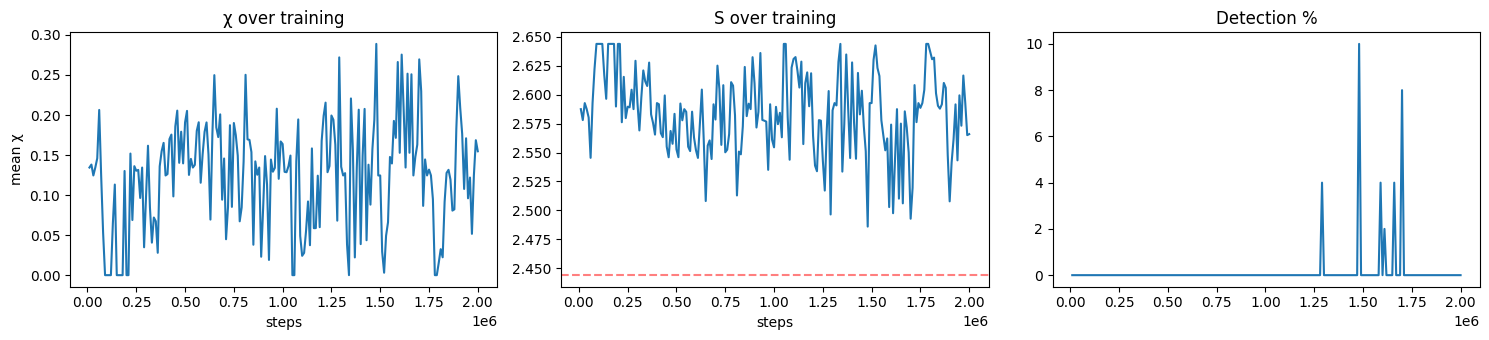

In [12]:
if best_cb.history:
    hist = pd.DataFrame(best_cb.history)
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
    ax[0].plot(hist['step'], hist['chi']); ax[0].set_title('χ over training')
    ax[0].set_xlabel('steps'); ax[0].set_ylabel('mean χ')
    ax[1].plot(hist['step'], hist['S']); ax[1].axhline(DET_THRESH, ls='--', c='r', alpha=0.5)
    ax[1].set_title('S over training'); ax[1].set_xlabel('steps')
    ax[2].plot(hist['step'], hist['det']*100); ax[2].set_title('Detection %')
    plt.tight_layout(); plt.show()

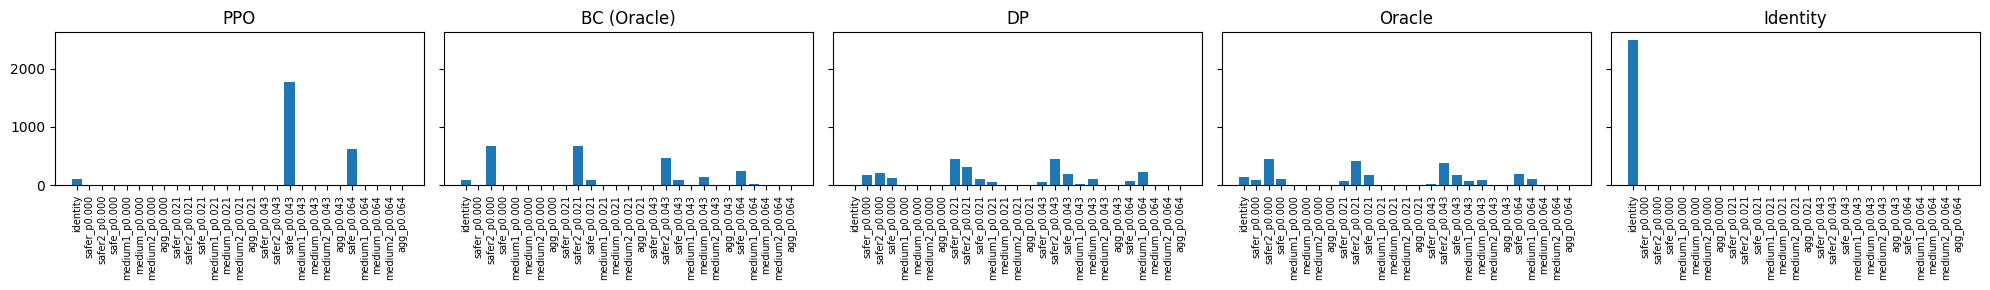

In [13]:
fig, axes = plt.subplots(1, len(POLICIES), figsize=(4*len(POLICIES), 3), sharey=True)
for ax, (name, r) in zip(axes, results.items()):
    counts = np.bincount(r['actions'], minlength=N_ACTIONS)
    ax.bar(range(N_ACTIONS), counts)
    ax.set_xticks(range(N_ACTIONS))
    ax.set_xticklabels([m['label'] for m in action_meta], rotation=90, fontsize=7)
    ax.set_title(name)
plt.tight_layout(); plt.show()

## Save results

In [14]:
with open('e91_exp5_results.pkl', 'wb') as f:
    pickle.dump({
        'results': results, 'history': best_cb.history,
        'config': {'S_ABS_TARGETS': S_ABS_TARGETS, 'P_GRID': P_GRID.tolist(),
                   'DET_THRESH': DET_THRESH,
                   'cells_built': [(p, lvl) for (p, lvl) in library.keys()]},
        'action_meta': action_meta,
    }, f)
torch.save(bc.state_dict(), 'bc_e91_exp5.pt')
print('Saved e91_exp5_results.pkl + bc_e91_exp5.pt')

Saved e91_exp5_results.pkl + bc_e91_exp5.pt
